# 01. Exploratory Data Analysis -SDNET2018 bridge decks

Goal: understand the deck subset before modelling – class balance, image appearance,
brightness/contrast, and whether simple edge features can separate the classes.


In [10]:
import random
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repo root: works whether Jupyter starts in the repo root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent

DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_DIR.exists(), f"{DATA_DIR} not found. Run: python src/prepare_data.py"

# Project constants
SPLITS = ["train", "val", "test"]
CLASSES = ["cracked", "uncracked"]
COLORS = {"cracked": "#d1495b", "uncracked": "#30638e"}
SEED = 42

# Reproducible random sampling
random.seed(SEED)
np.random.seed(SEED)

# Consistent plot style
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

print("Data folder:", DATA_DIR)

Data folder: c:\Users\zeris\deck-crack-detection\data\processed


In [11]:
rows = [
    {"split": split, "label": label, "path": path}
    for split in SPLITS
    for label in CLASSES
    for path in sorted((DATA_DIR / split / label).glob("*.jpg"))
]
df = pd.DataFrame(rows)

print(f"Total images: {len(df)}")
df.head()


Total images: 13620


,split,label,path
0,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...
1,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...
2,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...
3,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...
4,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...


In [12]:
counts = df.groupby(["split", "label"]).size().unstack().reindex(SPLITS)
counts["% cracked"] = (100 * counts["cracked"] / counts[CLASSES].sum(axis=1)).round(1)

counts

label,cracked,uncracked,% cracked
split,,,
train,1417,8116,14.9
val,304,1740,14.9
test,304,1739,14.9


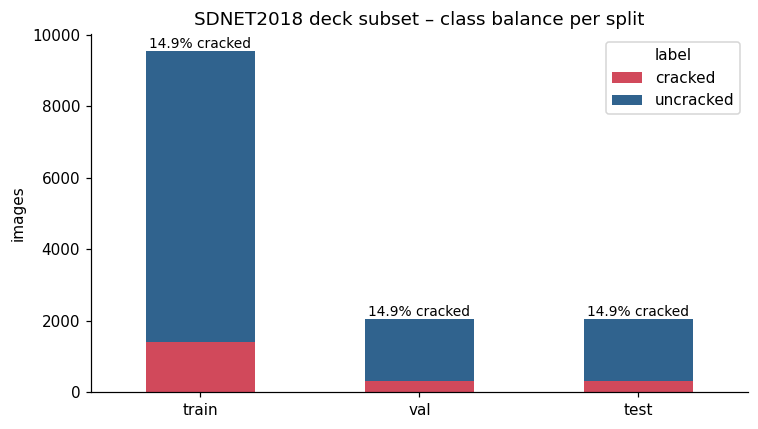

In [13]:
ax = counts[CLASSES].plot.bar(
    stacked=True,
    color=[COLORS[label] for label in CLASSES],
    figsize=(7, 4),
    rot=0,
)

ax.set_title("SDNET2018 deck subset – class balance per split")
ax.set_xlabel("")
ax.set_ylabel("images")

# Annotate each bar with its share of cracked images
for i, split in enumerate(SPLITS):
    bar_height = counts.loc[split, CLASSES].sum()
    ax.text(
        i,
        bar_height,
        f"{counts.loc[split, '% cracked']}% cracked",
        ha="center",
        va="bottom",
        fontsize=9,
    )

plt.tight_layout()
plt.savefig(FIG_DIR / "01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
train_counts = counts.loc["train", CLASSES]
n_train = train_counts.sum()

# A "model" that always predicts the majority class
baseline_accuracy = train_counts["uncracked"] / n_train

# Inverse-frequency weights: weight = total / (n_classes * class_count)
class_weight = {
    label: round(float(n_train / (len(CLASSES) * train_counts[label])), 2)
    for label in CLASSES
}

print(f"Always-'uncracked' accuracy: {baseline_accuracy:.1%}")
print("Class weights:", class_weight)

Always-'uncracked' accuracy: 85.1%
Class weights: {'cracked': 3.36, 'uncracked': 0.59}


### Takeaways – class balance

- Only ~15% of deck images are cracked, identical across train/val/test (stratified split works).
- A model that always says "uncracked" already reaches 85.1% accuracy → accuracy is not a useful metric here.
- We will report recall (cracked), precision, F1 and PR-AUC, and train with class weights (cracked ≈ 3.36, uncracked ≈ 0.59).


## 2. What the model sees - sample images


In [15]:
def load_rgb(path):
    """Read an image from disk and convert OpenCV's BGR order to RGB."""
    image = cv2.imread(str(path))
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


sample = load_rgb(df["path"].iloc[0])

print("Shape:", sample.shape)  # (height, width, channels)
print("Dtype:", sample.dtype)
print("Pixel range:", sample.min(), "to", sample.max())

Shape: (256, 256, 3)
Dtype: uint8
Pixel range: 90 to 225


In [16]:
def show_samples(label, n_images=12, n_cols=6, split="train", seed=SEED, save=True):
    """Plot a grid of random images from one class."""
    subset = df[(df["split"] == split) & (df["label"] == label)]
    paths = subset["path"].sample(n_images, random_state=seed)

    n_rows = int(np.ceil(n_images / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(n_cols * 1.8, n_rows * 1.8), squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, path in zip(axes.flat, paths):
        ax.imshow(load_rgb(path))

    fig.suptitle(f"{label} ({split})", color=COLORS[label], fontsize=13)
    plt.tight_layout()

    if save:
        plt.savefig(FIG_DIR / f"02_samples_{label}.png", dpi=150, bbox_inches="tight")
    plt.show()

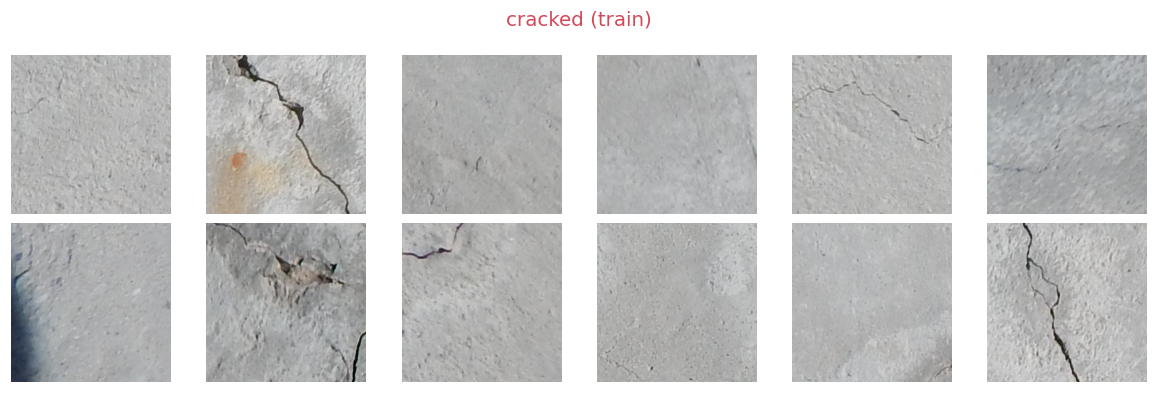

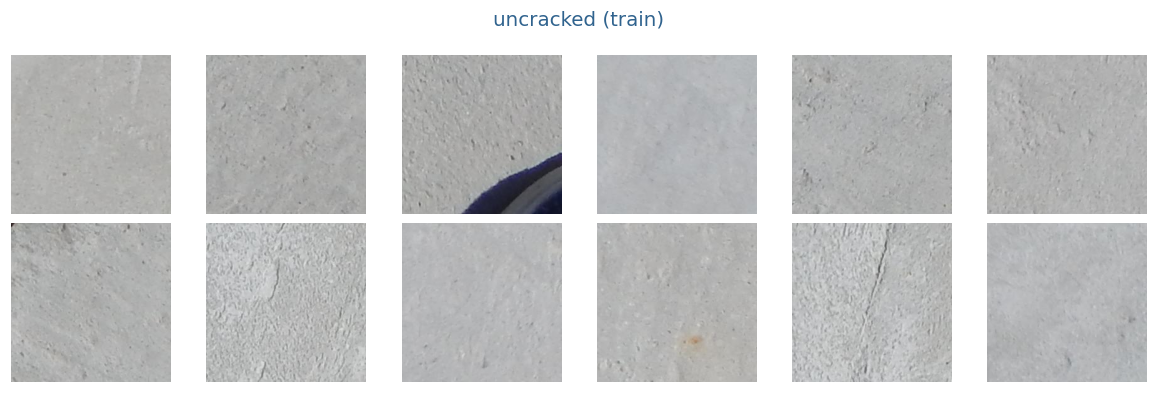

In [17]:
for label in CLASSES:
    show_samples(label)
    

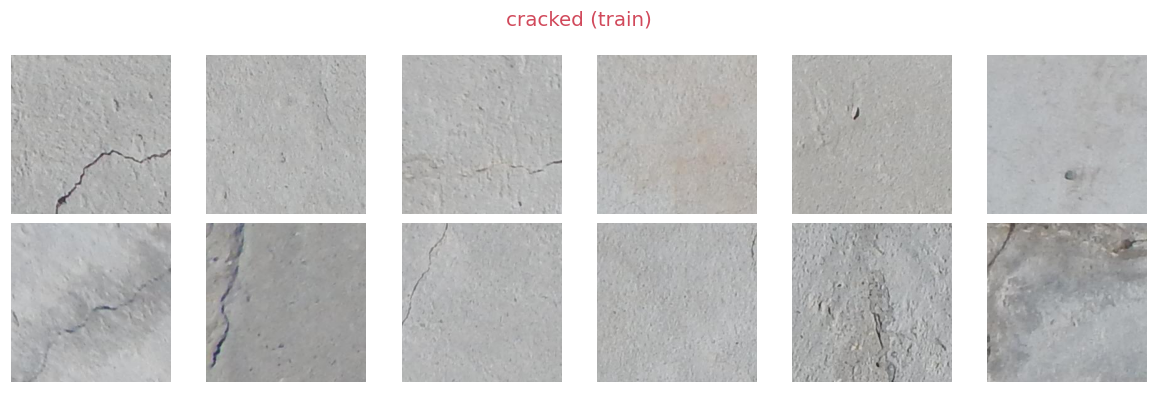

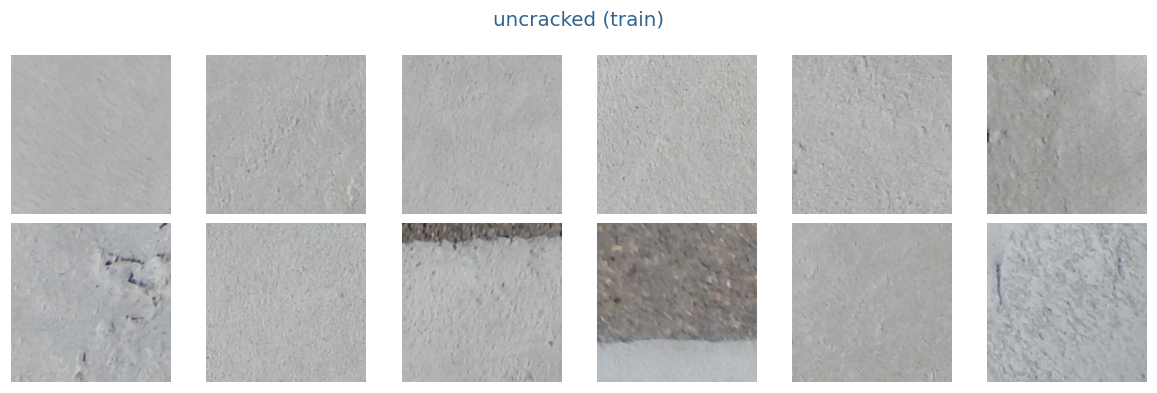

In [18]:
# Change the seed to see different images – look at at least 3 seeds per class
show_samples("cracked", seed=1, save=False)
show_samples("uncracked", seed=1, save=False)

### Takeaways – visual inspection

- **Cracked images:** crack widths range from 0.06mm to ; orientation is mostly at the edge; cracks are centered in the image.
- **Uncracked images:** contain aggregate texture and construciton default that looks like a crack and make the model effiecent.
- **Hard cases:** Some of the uncrack sample are difficult to put them in the crack label
- **Possible label errors:** some of the crack are difficult to class them
- **Implication for modelling:** random rotations are safe because cracks have no fixed orientation; brightness augmentation helps because lighting varies.


## 3. Brightness and contrast per class


In [19]:
def image_stats(path):
    """Return basic size and intensity statistics for one image."""
    image = cv2.imread(str(path))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return {
        "height": image.shape[0],
        "width": image.shape[1],
        "brightness": gray.mean(),
        "contrast": gray.std(),
    }

# Balanced sample from the TRAIN split only (never explore the test set)
SAMPLE_PER_CLASS = 1000

stats_df = (
    df[df["split"] == "train"]
    .groupby("label")
    .sample(n=SAMPLE_PER_CLASS, random_state=SEED)
    .reset_index(drop=True)
)
stats = pd.DataFrame([image_stats(path) for path in stats_df["path"]])
stats_df = pd.concat([stats_df, stats], axis=1)

print(f"Analysed {len(stats_df)} images")
stats_df.head()

Analysed 2000 images


,split,label,path,height,width,brightness,contrast
0,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...,256,256,180.898651,8.887670
1,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...,256,256,178.142258,24.335605
2,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...,256,256,169.952164,6.856054
3,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...,256,256,176.979034,7.017855
4,train,cracked,c:\Users\zeris\deck-crack-detection\data\proce...,256,256,181.248962,9.049752


In [20]:
stats_df[["height", "width"]].value_counts()

height  width
256     256      2000
Name: count, dtype: int64

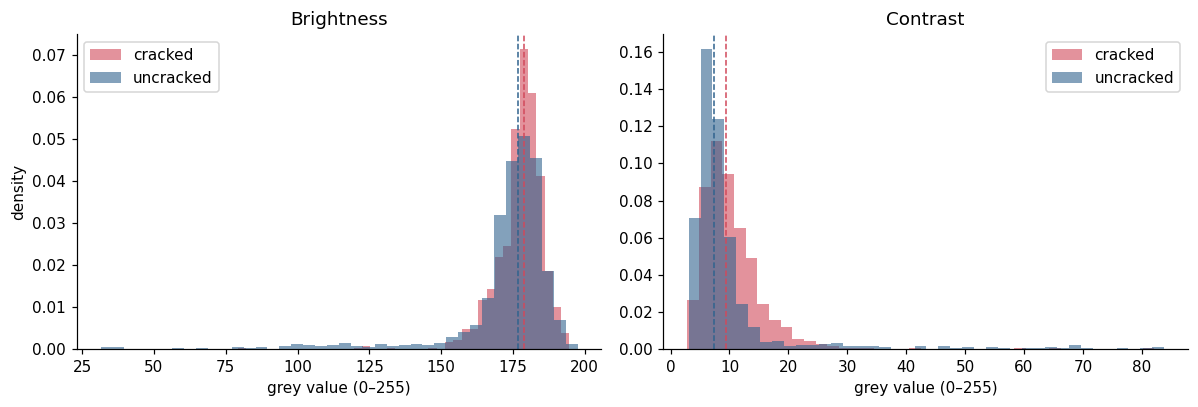

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for ax, feature in zip(axes, ["brightness", "contrast"]):
    for label in CLASSES:
        values = stats_df.loc[stats_df["label"] == label, feature]
        ax.hist(values, bins=40, density=True, alpha=0.6, color=COLORS[label], label=label)
        ax.axvline(values.median(), color=COLORS[label], linestyle="--", linewidth=1)
    ax.set_title(feature.capitalize())
    ax.set_xlabel("grey value (0–255)")
    ax.legend()

axes[0].set_ylabel("density")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_brightness_contrast.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
summary = (
    stats_df.groupby("label")[["brightness", "contrast"]]
    .agg(["mean", "median", "std"])
    .round(1)
)
summary

brightness              contrast             
                mean median   std     mean median   std
label                                                  
cracked        177.5  178.8   8.5     10.4    9.4   5.6
uncracked      172.7  177.0  19.0      9.9    7.3  10.1

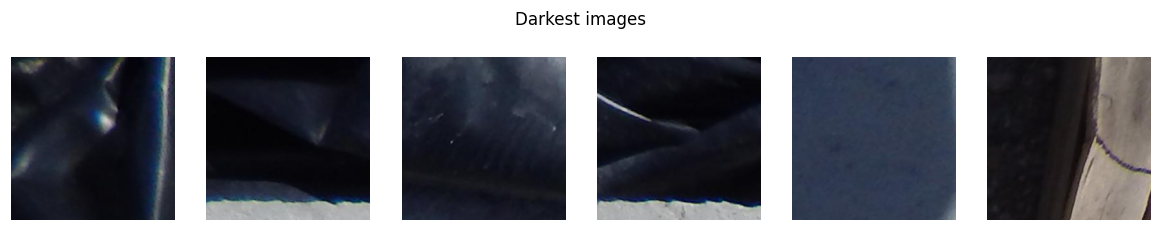

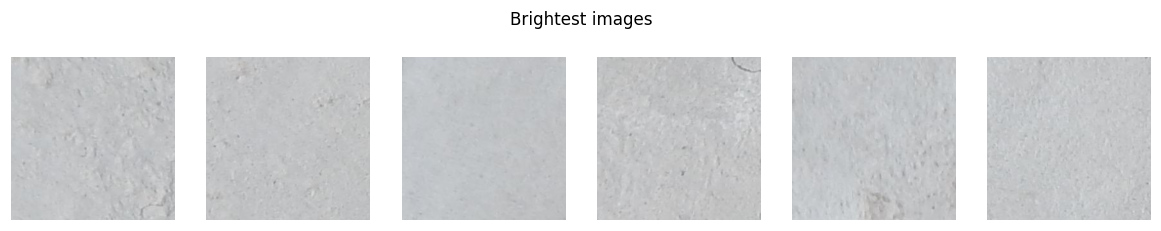

Darkest 50:  {'uncracked': 46, 'cracked': 4}
Brightest 50: {'uncracked': 27, 'cracked': 23}


In [23]:
def show_images(paths, title, n_cols=6):
    """Plot a single row of images with a title."""
    fig, axes = plt.subplots(1, n_cols, figsize=(n_cols * 1.8, 2.1))
    for ax, path in zip(axes, paths):
        ax.imshow(load_rgb(path))
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


ranked = stats_df.sort_values("brightness")

show_images(ranked["path"].head(6), "Darkest images")
show_images(ranked["path"].tail(6), "Brightest images")

# Which class do the extremes belong to?
print("Darkest 50: ", ranked.head(50)["label"].value_counts().to_dict())
print("Brightest 50:", ranked.tail(50)["label"].value_counts().to_dict())

### Takeaways – brightness and contrast

- **Brightness bias:** of the 50 darkest train images (balanced sample), 46 are uncracked (expected ≈ 25).
  Dark images are strongly associated with "uncracked"; bright images are not (27 vs 23).
- **Risk:** the model may learn "dark → no crack" and miss cracks in shadowed or wet areas (false negatives).
- **Mitigation:** brightness/contrast augmentation during training; later, check the recall on dark test images separately
  and use Grad-CAM to see whether the model looks at cracks or just at overall darkness.


- **Brightness bias:** of the 50 darkest train images (balanced sample), 46 are uncracked (expected ≈ 25).
  Dark images are strongly associated with "uncracked"; bright images are not (27 vs 23).
- **Risk:** the model may learn "dark → no crack" and miss cracks in shadowed or wet areas (false negatives).
- **Mitigation:** brightness/contrast augmentation during training; later, check the recall on dark test images separately
  and use Grad-CAM to see whether the model looks at cracks or just at overall darkness.


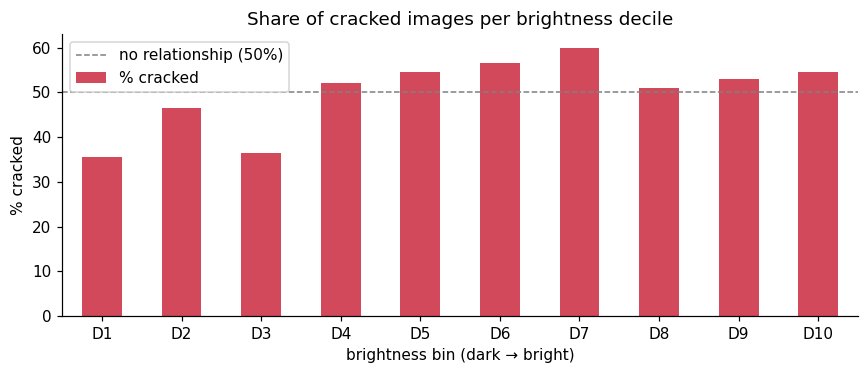

brightness_bin
(31.404, 165.426]     35.5
(165.426, 170.711]    46.5
(170.711, 173.992]    36.5
(173.992, 176.17]     52.0
(176.17, 178.036]     54.5
(178.036, 179.574]    56.5
(179.574, 181.292]    60.0
(181.292, 183.051]    51.0
(183.051, 185.666]    53.0
(185.666, 197.51]     54.5
Name: % cracked, dtype: float64

In [26]:
stats_df["brightness_bin"] = pd.qcut(stats_df["brightness"], q=10)

crack_share_by_brightness = (
    stats_df.groupby("brightness_bin", observed=True)["label"]
    .apply(lambda labels: (labels == "cracked").mean() * 100)
    .round(1)
    .rename("% cracked")
)

ax = crack_share_by_brightness.plot.bar(color=COLORS["cracked"], figsize=(8, 3.5))
ax.axhline(50, color="grey", linestyle="--", linewidth=1, label="no relationship (50%)")
ax.set_xlabel("brightness bin (dark → bright)")
ax.set_ylabel("% cracked")
ax.set_title("Share of cracked images per brightness decile")
ax.set_xticklabels([f"D{i}" for i in range(1, 11)], rotation=0)
ax.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "03_crack_share_by_brightness.png", dpi=150, bbox_inches="tight")
plt.show()

crack_share_by_brightness

- **Brightness bias (moderate, concentrated in the dark tail):** most images fall in a narrow brightness
  range (grey value ~165–197). In the darkest decile only 35.5% are cracked (balanced sample, expected 50%);
  among the 50 darkest images only 4 are cracked. Deciles D4–D10 are close to 50–60%.
- Brightness alone is a weak predictor overall, but the model may miss cracks in very dark (shadowed/wet) areas.
- **Mitigation:** brightness augmentation; evaluate recall separately on the darkest test images.


## 4. Mean image per class


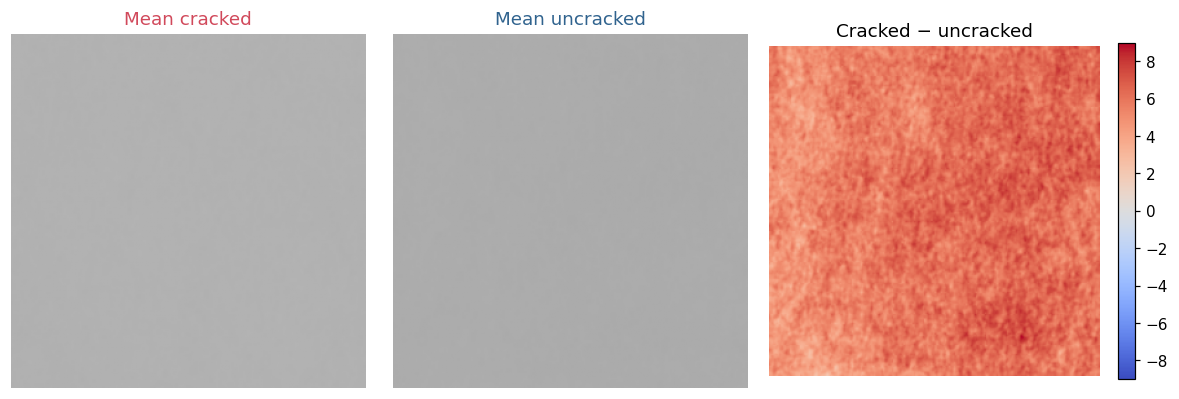

Max absolute difference: 9.0 grey levels


In [27]:
def mean_gray_image(label, n_images=500, split="train"):
    """Average n random grayscale images of one class."""
    subset = df[(df["split"] == split) & (df["label"] == label)]
    paths = subset["path"].sample(n_images, random_state=SEED)

    total = np.zeros((256, 256), dtype=np.float64)
    for path in paths:
        total += cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return total / n_images


mean_images = {label: mean_gray_image(label) for label in CLASSES}
difference = mean_images["cracked"] - mean_images["uncracked"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))

for ax, label in zip(axes[:2], CLASSES):
    ax.imshow(mean_images[label], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Mean {label}", color=COLORS[label])

limit = np.abs(difference).max()
im = axes[2].imshow(difference, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[2].set_title("Cracked − uncracked")
fig.colorbar(im, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_mean_images.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Max absolute difference: {limit:.1f} grey levels")

## 5. Edge density – a classical baseline


In [28]:
def edge_density(path, low=50, high=150):
    """Percentage of pixels marked as edges by the Canny detector."""
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    gray = cv2.GaussianBlur(gray, (5, 5), 0)  # suppress fine surface noise
    edges = cv2.Canny(gray, low, high)
    return (edges > 0).mean() * 100


stats_df["edge_density"] = [edge_density(path) for path in stats_df["path"]]

stats_df.groupby("label")["edge_density"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
cracked,1000.0,0.94,1.15,0.0,0.17,0.58,1.32,10.91
uncracked,1000.0,0.79,1.96,0.0,0.04,0.17,0.60,16.90


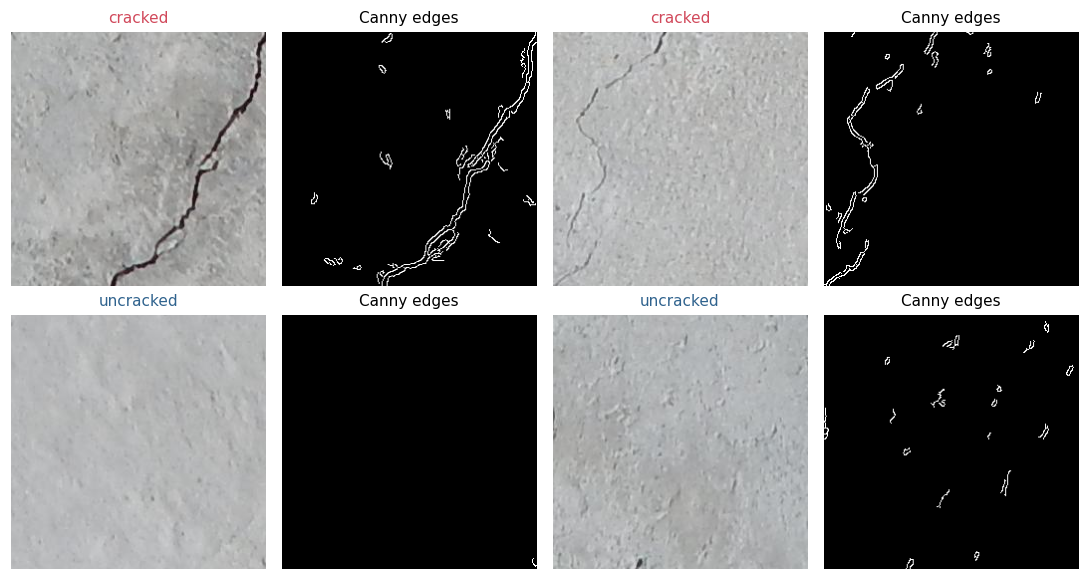

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))

for row, label in enumerate(CLASSES):
    paths = stats_df.loc[stats_df["label"] == label, "path"].sample(2, random_state=SEED)
    for col, path in enumerate(paths):
        gray = cv2.GaussianBlur(cv2.imread(str(path), cv2.IMREAD_GRAYSCALE), (5, 5), 0)
        axes[row, col * 2].imshow(load_rgb(path))
        axes[row, col * 2].set_title(label, color=COLORS[label], fontsize=10)
        axes[row, col * 2 + 1].imshow(cv2.Canny(gray, 50, 150), cmap="gray")
        axes[row, col * 2 + 1].set_title("Canny edges", fontsize=10)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "05_canny_examples.png", dpi=150, bbox_inches="tight")
plt.show()

In [30]:
from sklearn.metrics import roc_auc_score

y_true = (stats_df["label"] == "cracked").astype(int)

feature_auc = pd.Series(
    {
        feature: roc_auc_score(y_true, stats_df[feature])
        for feature in ["brightness", "contrast", "edge_density"]
    },
    name="ROC-AUC",
).round(3)

feature_auc

brightness      0.567
contrast        0.643
edge_density    0.650
Name: ROC-AUC, dtype: float64

## 6. EDA summary

- **Data:** 13,620 deck images, 256×256 RGB, 14.9% cracked, stratified 70/15/15 split.
- **Metric choice:** always-"uncracked" gives 85.1% accuracy → report recall, precision, F1, PR-AUC.
- **Class weights:** cracked ≈ 3.36, uncracked ≈ 0.59.
- **Brightness:** weak signal overall, but dark images are mostly uncracked → brightness augmentation, check recall on dark images.
- **Position:** mean images show (no) spatial bias → flips/rotations are safe.
- **Classical baseline:** best handcrafted feature AUC = … → simple features are (not) enough; a CNN is needed.
